# 03 – Machine-learning models vs baselines
Trains three regression methods taught in MMA3001 Week 5 – **linear regression**, **decision tree regression** and **neural network (MLP) regression** – to forecast each space's 15-minute headcount one day ahead, and compares them with the baselines from notebook 02 on the same test period (1 Jul 2025 – Apr 2026).

**Target:** beat the best baseline on each metric (in notebook 02: MAE 0.540, RMSE 1.055, F1 0.678; recomputed below on the exact intervals the models are scored on).

In [2]:
import sys
sys.path.insert(0, "../src")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from occforecast.load import load_occupancy
from occforecast.resample import resample_all
from occforecast.baselines import weekly_profile, persistence
from occforecast.evaluate import score
from occforecast.model import make_features, make_model, fit_predict, feature_importance, FEATURES

DATA = "../data/raw/5occupancySensor_MayToDec2024_9MRows.csv"
SPLIT = pd.Timestamp("2025-07-01", tz="Australia/Melbourne")

events = load_occupancy(DATA)
series = resample_all(events, freq="15min", max_hold="48h").sort_index()
labels = {s: f"Space {chr(65 + i)}" for i, s in enumerate(sorted(events["space"].unique()))}
series["label"] = series["space"].map(labels)

## 1. Features
Every feature must be known **24 hours before** the interval being forecast (the forecast is issued a day ahead), otherwise validation results would be over-optimistic. A unit test (`test_no_leakage_from_last_24_hours`) checks this.

| Feature | Meaning |
|---|---|
| `hour`, `day_of_week`, `is_weekend` | Calendar position |
| `is_holiday` | Victorian public holiday or university shutdown (22 Dec – 7 Jan, from the audit) |
| `tod_sin`, `tod_cos` (+ 2nd harmonics) | Time of day on a circle, so 23:45 is next to 00:00 (needed by linear/MLP) |
| `lag_1d`, `lag_7d` | Headcount 1 and 7 days earlier |
| `profile_4w` | Mean of the same slot 7, 14, 21, 28 days earlier (adaptive weekly profile) |
| `recent_mean_7d` | Mean headcount over the 7 days ending 24 h earlier (term vs. break activity level) |

Missing lag values are filled with the training median, so all models are scored on exactly the same intervals as the baselines.

## 2. Train and score all methods
Each space gets its own models (trained on data before 1 Jul 2025). All methods are scored on exactly the same test intervals (those where every method has a forecast; 7-day persistence has none where the week-earlier value is missing). Fit and predict times are recorded for the performance section.

In [3]:
MODELS = ["linear", "tree", "mlp"]
NAMES = {"linear": "Linear regression", "tree": "Decision tree", "mlp": "Neural network (MLP)"}

results, forecasts, trees, timings = [], {}, {}, []
for name, g in series.groupby("label"):
    y = g["headcount_mean"]
    train, test = y[y.index < SPLIT], y[y.index >= SPLIT].dropna()
    if test.empty or train.dropna().empty:
        print(f"{name}: skipped (no data on one side of the split)")
        continue

    t0 = time.perf_counter()
    X = make_features(y)
    timings.append({"Space": name, "Step": "Features", "Seconds": time.perf_counter() - t0})

    preds = {
        "Weekly profile": weekly_profile(train, test.index),
        "Persistence (7 days)": persistence(y, test.index, lag="7D"),
    }
    for m in MODELS:
        model = make_model(m)
        t0 = time.perf_counter()
        preds[NAMES[m]] = fit_predict(y, SPLIT, model, features=X).reindex(test.index)
        timings.append({"Space": name, "Step": NAMES[m], "Seconds": time.perf_counter() - t0})
        if m == "tree":
            trees[name] = model

    f = pd.DataFrame({"Actual": test, **preds})
    common = f.notna().all(axis=1)          # score every method on the same intervals
    forecasts[name] = f[common]
    for method in preds:
        results.append({"Space": name, "Method": method, **score(f.loc[common, "Actual"], f.loc[common, method])})
    print(f"{name}: done ({common.sum():,} of {len(f):,} test intervals scored)")

table = pd.DataFrame(results).set_index(["Space", "Method"])
display(table.round(3))

Space A: done (28,413 of 28,413 test intervals scored)
Space B: done (28,409 of 28,409 test intervals scored)
Space C: skipped (no data on one side of the split)
Space D: done (28,413 of 28,413 test intervals scored)
Space E: done (28,100 of 28,256 test intervals scored)


MAE   RMSE     F1      n
Space   Method                                          
Space A Weekly profile        0.378  0.704  0.674  28413
        Persistence (7 days)  0.324  0.898  0.707  28413
        Linear regression     0.305  0.673  0.740  28413
        Decision tree         0.290  0.690  0.752  28413
        Neural network (MLP)  0.295  0.665  0.766  28413
Space B Weekly profile        0.620  0.906  0.522  28409
        Persistence (7 days)  0.561  0.899  0.445  28409
        Linear regression     0.481  0.718  0.545  28409
        Decision tree         0.496  0.790  0.530  28409
        Neural network (MLP)  0.486  0.744  0.539  28409
Space D Weekly profile        0.389  0.632  0.806  28413
        Persistence (7 days)  0.387  0.739  0.814  28413
        Linear regression     0.367  0.590  0.824  28413
        Decision tree         0.354  0.608  0.830  28413
        Neural network (MLP)  0.352  0.574  0.827  28413
Space E Weekly profile        0.810  1.979  0.712  28100
        Persistence (7 days)  0.889  2.627  0.659  28100
        Linear regression     0.767  1.953  0.723  28100
        Decision tree         0.793  2.057  0.724  28100
        Neural network (MLP)  0.789  2.057  0.731  28100

## 3. Average over spaces, compared with the targets

In [4]:
order = ["Weekly profile", "Persistence (7 days)"] + [NAMES[m] for m in MODELS]
mean = table.groupby("Method")[["MAE", "RMSE", "F1"]].mean().loc[order]
# Targets = best baseline on each metric (same intervals as the models)
base = mean.loc[["Weekly profile", "Persistence (7 days)"]]
targets = {"MAE": base["MAE"].min(), "RMSE": base["RMSE"].min(), "F1": base["F1"].max()}
print("Targets:", {k: round(float(v), 3) for k, v in targets.items()})
mean["Beats best baseline on all 3"] = ((mean["MAE"] < targets["MAE"]) & (mean["RMSE"] < targets["RMSE"])
                                        & (mean["F1"] > targets["F1"]))
for metric in ["MAE", "RMSE"]:
    mean[f"{metric} vs best baseline (%)"] = 100 * (mean[metric] - targets[metric]) / targets[metric]
display(mean.round(3))

Targets: {'MAE': 0.54, 'RMSE': 1.055, 'F1': 0.679}


,MAE,RMSE,F1,Beats best baseline on all 3,MAE vs best baseline (%),RMSE vs best baseline (%)
Method,,,,,,
Weekly profile,0.549,1.055,0.679,False,1.669,0.000
Persistence (7 days),0.540,1.291,0.656,False,0.000,22.308
Linear regression,0.480,0.983,0.708,True,-11.155,-6.829
Decision tree,0.483,1.036,0.709,True,-10.535,-1.823
Neural network (MLP),0.480,1.010,0.716,True,-11.078,-4.288


**Findings:** all three ML models beat the best baseline on every metric, improving MAE by ≈ 11% (0.540 → 0.480), RMSE by 2–7% and F1 from 0.679 to 0.708–0.716. The three models are within ≈ 1% of each other, so the improvement comes mainly from the features rather than model complexity: linear regression matches the MLP's MAE and has the lowest RMSE (0.983). Space B improves most (MAE 0.620 → 0.481, −22%). Space E barely improves, and the tree and MLP have a slightly worse RMSE there than the weekly profile (2.06 vs 1.98), because its large one-off events are not predictable from calendar and history. Model choice is deferred to the rolling-origin validation in notebook 04.

## 4. What does the decision tree rely on?
Feature importance = how much each feature reduces the tree's squared error, summed over all splits that use it (normalised to sum to 1), averaged over spaces.

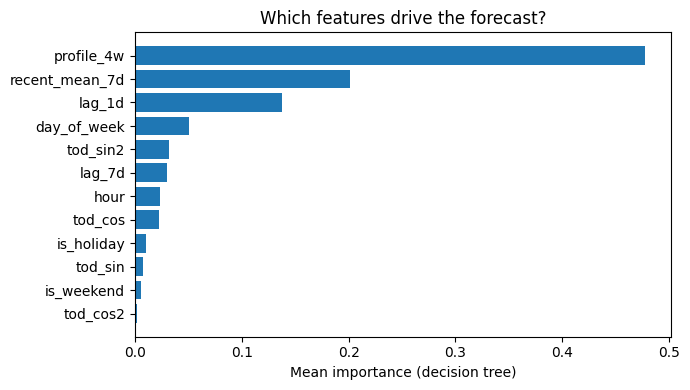

,Space A,Space B,Space D,Space E,Mean
profile_4w,0.462,0.453,0.609,0.386,0.478
recent_mean_7d,0.127,0.289,0.097,0.293,0.202
lag_1d,0.208,0.082,0.112,0.148,0.138
day_of_week,0.046,0.050,0.041,0.064,0.050
tod_sin2,0.050,0.026,0.033,0.020,0.032
lag_7d,0.029,0.042,0.012,0.035,0.030
hour,0.024,0.020,0.026,0.022,0.023
tod_cos,0.027,0.021,0.025,0.017,0.023
is_holiday,0.014,0.003,0.021,0.002,0.010
tod_sin,0.007,0.006,0.007,0.009,0.007


In [5]:
imp = pd.DataFrame({name: feature_importance(m) for name, m in trees.items()})
imp["Mean"] = imp.mean(axis=1)
imp = imp.sort_values("Mean")
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp["Mean"])
ax.set_xlabel("Mean importance (decision tree)")
ax.set_title("Which features drive the forecast?")
plt.tight_layout(); plt.show()
display(imp.sort_values("Mean", ascending=False).round(3))

**Findings:** the tree relies mostly on recent history: the 4-week same-slot average (`profile_4w`, 0.48), the 7-day activity level (`recent_mean_7d`, 0.20) and yesterday's value (`lag_1d`, 0.14). Calendar flags have low importance (`is_holiday` 0.01). This does not mean holidays don't matter: `recent_mean_7d` already drops during breaks, so the tree rarely needs the flag. Importance measures what the tree *used*, not what is physically important.

## 5. Forecast vs actual for one test week

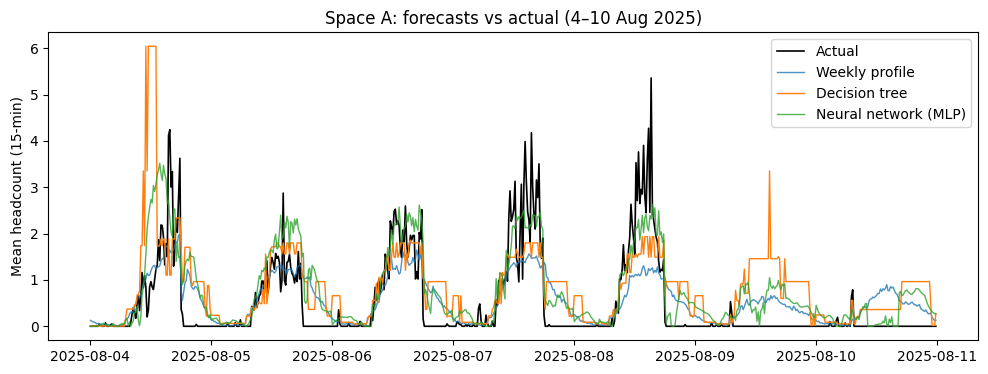

In [6]:
name = "Space A"
wk = forecasts[name].loc["2025-08-04":"2025-08-10"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(wk.index, wk["Actual"], color="black", lw=1.2, label="Actual")
ax.plot(wk.index, wk["Weekly profile"], lw=1, alpha=0.8, label="Weekly profile")
ax.plot(wk.index, wk["Decision tree"], lw=1, label="Decision tree")
ax.plot(wk.index, wk["Neural network (MLP)"], lw=1, alpha=0.8, label="Neural network (MLP)")
ax.set_ylabel("Mean headcount (15-min)")
ax.set_title(f"{name}: forecasts vs actual (4–10 Aug 2025)")
ax.legend(); plt.show()

**Findings:** all models follow the daily shape but underestimate short peaks (actual 4–5, forecast ≈ 2). The decision tree's forecasts are step-shaped, because each leaf predicts a constant, which produces visible plateaus overnight and at weekends and a large over-forecast early on Monday. The MLP gives the smoothest, most realistic shape.

## 6. Where do the errors come from?
Mean absolute error split by time of day and by day type, for the best baseline and the models. This shows *where* each method fails, not just how much.

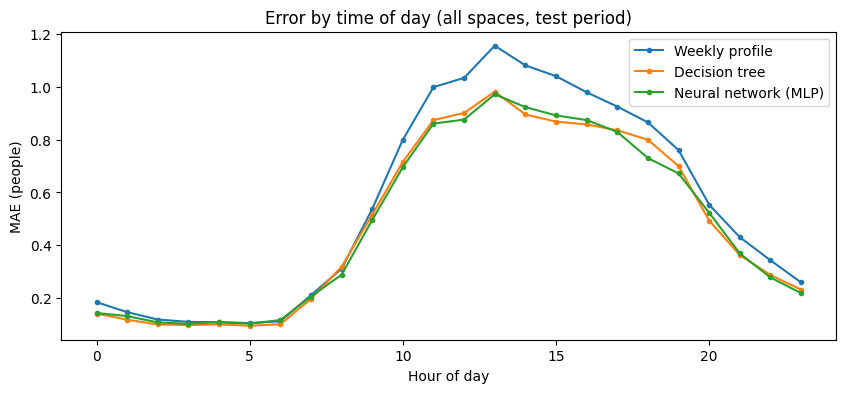

,Weekly profile,Persistence (7 days),Linear regression,Decision tree,Neural network (MLP)
Holiday/shutdown,0.643,0.396,0.310,0.290,0.263
Weekday,0.608,0.644,0.550,0.566,0.569
Weekend,0.371,0.325,0.357,0.336,0.326


In [7]:
from occforecast.model import holiday_flags

all_f = pd.concat(forecasts.values())
err = all_f.drop(columns="Actual").sub(all_f["Actual"], axis=0).abs()
hours = all_f.index.hour
day_type = np.where(holiday_flags(all_f.index) == 1, "Holiday/shutdown",
                    np.where(all_f.index.day_of_week >= 5, "Weekend", "Weekday"))

fig, ax = plt.subplots(figsize=(10, 4))
for col in ["Weekly profile", "Decision tree", "Neural network (MLP)"]:
    ax.plot(err[col].groupby(hours).mean(), marker="o", ms=3, label=col)
ax.set_xlabel("Hour of day"); ax.set_ylabel("MAE (people)")
ax.set_title("Error by time of day (all spaces, test period)")
ax.legend(); plt.show()

display(err.groupby(day_type).mean()[order].round(3))

**Findings:** errors are concentrated in working hours, peaking around 13:00 (MAE ≈ 1 person); overnight errors are ≈ 0.1. The models improve on the weekly profile mainly between 10:00 and 17:00. The largest gain is on holidays and shutdown days, where MAE falls from 0.64 (weekly profile) to 0.26–0.31: the profile cannot know a day is a holiday, but the recent-history features detect the drop in activity. Weekday gains are smaller (0.61 → 0.55–0.57) and weekend errors are similar for all methods.

## 7. Run time

In [8]:
tt = pd.DataFrame(timings).groupby("Step")["Seconds"].agg(["mean", "sum"]).round(2)
display(tt)

,mean,sum
Step,,
Decision tree,0.20,0.80
Features,0.98,3.91
Linear regression,0.05,0.21
Neural network (MLP),8.06,32.24


**Findings:** per space, building features takes ≈ 1 s, linear regression trains and predicts in 0.05 s, the decision tree in 0.2 s, and the MLP in ≈ 8 s (≈ 160× slower than linear) for essentially the same accuracy. For a building system retraining many spaces regularly, linear regression or the tree is far more practical.